<div style="background-color:#F5EDE0; border:1px solid #C9A961; border-radius:10px; padding:34px 24px; text-align:center;">
  <div style="color:#8C7B6B; font-size:13px; letter-spacing:5px;">PLANIFICADOR DE COSTOS DE LA JORNADA</div>
  <div style="color:#7A5C1E; font-size:40px; font-family:Georgia, 'Times New Roman', serif; margin:12px 0;">Sunny Side Luxury Spa</div>
  <div style="color:#4A3F35; font-size:16px;">Personal, insumos, ingresos y ganancia estimada para cada jornada</div>
  <div style="color:#8C7B6B; font-size:12px; margin-top:16px;">Proyecto final · ADMI 1301 Introducción a la Programación · Universidad de los Andes · 2026-2</div>
</div>
Integrantes: Matias Galeano (202523711) · Emily Rojas (202523724) · Paloma Restrepo (202410702) · Valeria Nuncio (202524226)

## Cómo usar esta herramienta

Sunny Side Luxury Spa es un spa ficticio de lujo. Esta herramienta ayuda al administrador a responder: *si espero cierta cantidad de clientes, ¿cuánto personal necesito, cuánto gasto, cuánto ingreso y cuánta ganancia operativa puedo esperar?*

**Tres pasos**
1. Ejecuten todas las celdas en orden (menú Entorno de ejecución → Ejecutar todo). No necesita archivos externos.
2. Vayan a la sección **4 · Calculadora**, escriban la cantidad de clientes esperados y ejecuten esa celda.
3. Vean la comparación de baja afluencia, ocupación media y agenda llena en la sección **5**.

> **Importante:** todas las cifras de este notebook (precios, costos, capacidades) son supuestos de simulación propuestos por el grupo. No son datos reales de ninguna empresa

**Contenido:** 1 · El problema · 2 · Supuestos · 3 · Motor de cálculo · 4 · Calculadora · 5 · Comparación de escenarios · 6 · Verificación matemática · 7 · Interpretación  · 8 · Limitaciones · 9 · Uso de IA


## 1 · El problema, el usuario y la utilidad

**Problema.** Un spa de lujo cobra precios altos y trabaja con personal especializado. Si el administrador contrata de más, gasta sin necesidad. Si contrata de menos, no puede atender las reservas y pierde ingresos y reputación.

**Usuario.** El administrador o gerente de Sunny Side Luxury Spa.

**Utilidad.** Permite simular distintos niveles de demanda antes de armar los turnos, y entender cómo cambian los costos y la ganancia cuando cambia el número de clientes.

> **Nota académica.** Este notebook tiene dos usos: es una herramienta para el administrador y es nuestro proyecto de programación. Por eso, cada sección de uso viene acompañada de una explicación de cómo está programada.

## 2 · Supuestos de simulación

>  Ninguna de estas cifras proviene de una empresa real ni de una fuente externa. Son propuestas del grupo, razonadas para que la simulación sea coherente. Cada una es una variable que se puede cambiar en la celda de código de esta sección.

| Supuesto | Valor | Cómo lo justificamos | Qué afecta |
|---|---|---|---|
| Clientes por terapeuta por turno | 3 | Turno de 8 horas. Un tratamiento de lujo dura cerca de 2 horas con preparación y limpieza, lo que daría un máximo teórico de 4 (8 ÷ 2). Usamos 3 para dejar margen por pausas, retrasos y tratamientos más largos. | Terapeutas necesarios y capacidad máxima |
| Clientes por persona de recepción/apoyo | 10 | Cada cliente necesita llegada, cobro y coordinación, y la recepción también atiende llamadas y reservas. Elegimos un número bajo porque un spa de lujo promete atención personalizada. | Personal de recepción |
| Costo del turno de terapeuta | $200.000 | Salario y prestaciones estimados de un turno de una profesional especializada. Chequeo de coherencia: con unos 26 turnos al mes serían cerca de $5,2 millones mensuales. | Costo de personal |
| Costo del turno de recepción/apoyo | $120.000 | Menor que el de terapeuta por ser un cargo menos especializado. Con 26 turnos al mes serían cerca de $3,1 millones. | Costo de personal |
| Cabinas | 8 | Suponemos una cabina por terapeuta trabajando al mismo tiempo. Capacidad máxima = 8 cabinas × 3 clientes = 24 clientes. | Capacidad máxima y escenarios |
| Precios: $200.000 / $260.000 / $360.000 | Masaje / Facial / Ritual | Posicionamiento de lujo: el masaje es el tratamiento base, el facial es más especializado y el ritual corporal es el más completo. No se tomaron de ningún spa real. | Ingresos |
| Insumos: $30.000 / $50.000 / $90.000 | Masaje / Facial / Ritual | Equivalen aproximadamente al 15 %, 19 % y 25 % del precio. El ritual usa más productos (aceites, mascarillas, envolturas). | Costo de insumos |
| Mezcla de tratamientos: 50 % / 30 % / 20 % | Masaje / Facial / Ritual | Suponemos que el masaje es el más solicitado y el ritual el menos frecuente por ser el más costoso. | Ingresos e insumos |
| Escenarios | 33 % / 67 % / 100 % de la capacidad | Baja, media y llena. Con 24 de capacidad máxima dan 8, 16 y 24 clientes. | Comparación |

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Paleta de colores del spa (códigos hexadecimales)
color_fondo = "#FBF7EF"      # crema
color_oro = "#B8923A"        # dorado
color_taupe = "#8C7B6B"      # gris pardo
color_arena = "#BFA27A"      # beige oscuro
color_salvia = "#6B8F71"     # verde suave (para la ganancia)


# Función auxiliar: convierte un número en texto con formato de pesos colombianos.
# Ejemplo: formato_cop(2040000) devuelve "$2.040.000"
def formato_cop(valor):
    texto = f"{abs(valor):,.0f}"       # separa los miles con coma: 2,040,000
    texto = texto.replace(",", ".")    # cambia la coma por punto: 2.040.000
    if valor < 0:
        return "-$" + texto
    return "$" + texto

In [ ]:
# ---------- SUPUESTOS DE SIMULACIÓN (propuestos por el grupo, modificables) ----------

# Personal
clientes_por_terapeuta = 3
clientes_por_recepcion = 10
costo_turno_terapeuta = 200000      # COP por turno
costo_turno_recepcion = 120000      # COP por turno

# Capacidad máxima planificada: una cabina por terapeuta
cabinas = 8
capacidad_maxima = cabinas * clientes_por_terapeuta

# Tratamientos: listas paralelas (posición 0 = masaje, 1 = facial, 2 = ritual)
nombres_servicios = ["Masaje relajante", "Facial hidratante premium", "Ritual corporal"]
nombres_cortos = ["Masaje", "Facial", "Ritual"]
precios = [200000, 260000, 360000]          # COP por cliente
costos_insumos = [30000, 50000, 90000]      # COP por cliente

# Mezcla de tratamientos (el masaje recibe el resto)
proporcion_facial = 0.30
proporcion_ritual = 0.20
proporcion_masaje = 1 - proporcion_facial - proporcion_ritual

# Escenarios: un tercio, dos tercios y el total de la capacidad máxima
nombres_escenarios = ["Baja afluencia", "Ocupación media", "Agenda llena"]
clientes_escenarios = [capacidad_maxima // 3, capacidad_maxima * 2 // 3, capacidad_maxima]

# ---------- Revisión de coherencia de los supuestos ----------
if proporcion_facial + proporcion_ritual > 1:
    print("ERROR: las proporciones de facial y ritual suman más de 100 %.")
else:
    print("Supuestos revisados: las proporciones son coherentes.")

# ---------- Resumen de los supuestos ----------
print()
print("Clientes por terapeuta por turno:", clientes_por_terapeuta)
print("Clientes por persona de recepción/apoyo por turno:", clientes_por_recepcion)
print("Costo de un turno de terapeuta:", formato_cop(costo_turno_terapeuta))
print("Costo de un turno de recepción/apoyo:", formato_cop(costo_turno_recepcion))
print("Capacidad máxima planificada:", capacidad_maxima, "clientes por jornada")
print("Clientes en cada escenario:", clientes_escenarios)
print()

precios_texto = []
insumos_texto = []
porcentaje_insumos = []
for i in range(len(nombres_servicios)):
    precios_texto.append(formato_cop(precios[i]))
    insumos_texto.append(formato_cop(costos_insumos[i]))
    porcentaje_insumos.append(f"{costos_insumos[i] / precios[i] * 100:.0f} %")

tabla_servicios = pd.DataFrame({
    "Tratamiento": nombres_servicios,
    "Precio por cliente": precios_texto,
    "Insumos por cliente": insumos_texto,
    "Insumos como % del precio": porcentaje_insumos,
    "% de la demanda": [
        f"{proporcion_masaje * 100:.0f} %",
        f"{proporcion_facial * 100:.0f} %",
        f"{proporcion_ritual * 100:.0f} %",
    ],
})
tabla_servicios

Supuestos revisados: las proporciones son coherentes.

Clientes por terapeuta por turno: 3
Clientes por persona de recepción/apoyo por turno: 10
Costo de un turno de terapeuta: $200.000
Costo de un turno de recepción/apoyo: $120.000
Capacidad máxima planificada: 24 clientes por jornada
Clientes en cada escenario: [8, 16, 24]



,Tratamiento,Precio por cliente,Insumos por cliente,Insumos como % del precio,% de la demanda
0,Masaje relajante,$200.000,$30.000,15 %,50 %
1,Facial hidratante premium,$260.000,$50.000,19 %,30 %
2,Ritual corporal,$360.000,$90.000,25 %,20 %


## 3 · Cálculos - formulas

Los cálculos están en funciones para usar exactamente la misma lógica con cualquier cantidad de clientes y en los tres escenarios.

**Fórmulas**

- **Personal necesario** = clientes ÷ capacidad del trabajador, **redondeado siempre hacia arriba**. Ejemplo: 9 clientes con capacidad 4 → 9 // 4 = 2 con resto 1 → se suma 1 → 3 personas.
- **Costo de personal** = terapeutas × costo del turno de terapeuta + recepción × costo del turno de recepción.
- **Clientes por tratamiento:** facial = clientes × 30 % redondeado; ritual = clientes × 20 % redondeado; masaje = los clientes restantes (así la suma siempre da el total).
- **Ingresos** = suma de (clientes del tratamiento × precio).
- **Costo de insumos** = suma de (clientes del tratamiento × costo de insumos).
- **Costos totales contemplados** = costo de personal + costo de insumos.
- **Ganancia operativa estimada** = ingresos − costos totales.
- **Margen** = ganancia ÷ ingresos × 100.
- **Utilización de terapeutas** = clientes ÷ (terapeutas × clientes por terapeuta) × 100.

**Regla de capacidad.** El spa tiene 8 cabinas y una terapeuta por cabina, así que atiende como máximo 24 clientes por jornada. Si la demanda supera 24, el programa **no calcula costos ni ganancia**, porque esa operación no es viable con la infraestructura disponible. Solo informa cuántos clientes quedarían sin atender.

**Cómo funciona el redondeo del reparto.** El 30 % de 5 clientes da 1,5 y el 30 % de 15 da 4,5. Python tiene una función `round()`, pero redondea los .5 hacia el número **par** más cercano (`round(1,5)` da 2 pero `round(4,5)` da 4), lo que daría resultados distintos para casos iguales. Por eso usamos `int(x + 0.5)`: `int()` corta los decimales y sumar 0,5 antes de cortar hace que todo .5 suba. Así, 1,5 da 2 y 4,5 da 5. El masaje recibe el resto para que el total nunca cambie. Con pocos clientes, el reparto no puede ser exactamente 50/30/20 (por ejemplo, con 1 cliente es 100 % masaje); la tabla de abajo lo muestra.



In [ ]:
# Función 1: cuántos trabajadores se necesitan (siempre redondeando hacia arriba)
def personal_necesario(clientes, capacidad):
    personal = clientes // capacidad          # división entera: cuántos grupos completos hay
    if clientes % capacidad > 0:              # % da el resto: si sobran clientes...
        personal = personal + 1               # ...hace falta un trabajador más
    return personal


# Función 2: reparte los clientes entre los tres tratamientos
def repartir_clientes(clientes):
    facial = int(clientes * proporcion_facial + 0.5)    # int(x + 0.5): todo .5 sube
    ritual = int(clientes * proporcion_ritual + 0.5)
    masaje = clientes - facial - ritual                 # el masaje recibe el resto
    return [masaje, facial, ritual]                     # mismo orden que nombres_servicios

In [ ]:
# Revisión del reparto: cómo se redondea con distintas cantidades de clientes
muestra = [1, 2, 5, 8, 10, 15, 16, 24]

col_clientes = []
col_masaje = []
col_facial = []
col_ritual = []
for n in muestra:
    reparto = repartir_clientes(n)
    col_clientes.append(n)
    col_masaje.append(f"{reparto[0]}  (resto)")
    col_facial.append(f"{n * proporcion_facial:.1f} → {reparto[1]}")
    col_ritual.append(f"{n * proporcion_ritual:.1f} → {reparto[2]}")

tabla_reparto = pd.DataFrame({
    "Clientes": col_clientes,
    "Masaje": col_masaje,
    "Facial (exacto → redondeado)": col_facial,
    "Ritual (exacto → redondeado)": col_ritual,
})
tabla_reparto

,Clientes,Masaje,Facial (exacto → redondeado),Ritual (exacto → redondeado)
0,1,1 (resto),0.3 → 0,0.2 → 0
1,2,1 (resto),0.6 → 1,0.4 → 0
2,5,2 (resto),1.5 → 2,1.0 → 1
3,8,4 (resto),2.4 → 2,1.6 → 2
4,10,5 (resto),3.0 → 3,2.0 → 2
5,15,7 (resto),4.5 → 5,3.0 → 3
6,16,8 (resto),4.8 → 5,3.2 → 3
7,24,12 (resto),7.2 → 7,4.8 → 5


In [ ]:
# Función 3: calcula todos los resultados de una jornada y los devuelve en un diccionario
def calcular_jornada(clientes):
    # Si la demanda supera la capacidad, la operación no es viable: no se calcula nada más
    if clientes > capacidad_maxima:
        return {
            "clientes": clientes,
            "viable": False,
            "clientes_sin_atender": clientes - capacidad_maxima,
        }

    # Personal
    terapeutas = personal_necesario(clientes, clientes_por_terapeuta)
    recepcion = personal_necesario(clientes, clientes_por_recepcion)
    costo_personal = terapeutas * costo_turno_terapeuta + recepcion * costo_turno_recepcion

    # Ingresos e insumos, tratamiento por tratamiento
    clientes_servicio = repartir_clientes(clientes)
    ingresos_servicio = []
    ingresos_total = 0
    costo_insumos_total = 0
    for i in range(len(nombres_servicios)):
        ingreso = clientes_servicio[i] * precios[i]
        insumos = clientes_servicio[i] * costos_insumos[i]
        ingresos_servicio.append(ingreso)
        ingresos_total = ingresos_total + ingreso
        costo_insumos_total = costo_insumos_total + insumos

    # Costos totales y ganancia
    costos_totales = costo_personal + costo_insumos_total
    ganancia = ingresos_total - costos_totales

    # Margen (evita dividir por cero si no hay clientes)
    if ingresos_total > 0:
        margen = ganancia / ingresos_total * 100
    else:
        margen = 0

    # Utilización de los terapeutas (evita dividir por cero)
    capacidad_contratada = terapeutas * clientes_por_terapeuta
    if capacidad_contratada > 0:
        utilizacion = clientes / capacidad_contratada * 100
    else:
        utilizacion = 0

    resultado = {
        "clientes": clientes,
        "viable": True,
        "clientes_sin_atender": 0,
        "terapeutas": terapeutas,
        "recepcion": recepcion,
        "clientes_servicio": clientes_servicio,
        "ingresos_servicio": ingresos_servicio,
        "costo_personal": costo_personal,
        "costo_insumos": costo_insumos_total,
        "costos_totales": costos_totales,
        "ingresos_total": ingresos_total,
        "ganancia": ganancia,
        "margen": margen,
        "utilizacion": utilizacion,
    }
    return resultado

In [ ]:
# Función 4: imprime el reporte de una jornada (no calcula nada, solo muestra)
def mostrar_reporte(r):
    print("=" * 60)
    print("REPORTE DE JORNADA · Sunny Side Luxury Spa")
    print("=" * 60)
    print(f"Clientes esperados: {r['clientes']}")

    # Si la jornada no es viable, solo se muestra la alerta y no hay cifras financieras
    if r["viable"] == False:
        print()
        print("*** NO SE PUEDE ATENDER ESTA DEMANDA ***")
        print(f"Capacidad máxima del spa: {capacidad_maxima} clientes por jornada")
        print(f"({cabinas} cabinas × {clientes_por_terapeuta} clientes por terapeuta).")
        print(f"Clientes que quedarían sin atender: {r['clientes_sin_atender']} de {r['clientes']}.")
        print()
        print("No se muestran costos, ingresos ni ganancia, porque esta")
        print("operación no es viable con la infraestructura disponible.")
        print(f"Reduzcan la demanda a {capacidad_maxima} clientes o menos,")
        print("o amplíen las cabinas en los supuestos de la sección 2.")
        print("=" * 60)
        return

    print()
    print("PERSONAL NECESARIO")
    print(f"  Terapeutas: {r['terapeutas']}  (utilización: {r['utilizacion']:.1f} %)")
    print(f"  Recepción/apoyo: {r['recepcion']}")

    print()
    print("INGRESOS POR TRATAMIENTO")
    for i in range(len(nombres_servicios)):
        print(f"  {nombres_servicios[i]}: {r['clientes_servicio'][i]} clientes → {formato_cop(r['ingresos_servicio'][i])}")
    print(f"  Ingresos totales: {formato_cop(r['ingresos_total'])}")

    print()
    print("COSTOS CONTEMPLADOS")
    print(f"  Costo de personal (turnos): {formato_cop(r['costo_personal'])}")
    print(f"  Costo de insumos: {formato_cop(r['costo_insumos'])}")
    print(f"  Costos totales: {formato_cop(r['costos_totales'])}")

    print()
    print("RESULTADO")
    print(f"  Ganancia operativa estimada: {formato_cop(r['ganancia'])}")
    print(f"  Margen sobre ingresos: {r['margen']:.1f} %")
    print("  (No incluye arriendo, servicios públicos ni impuestos)")
    print("=" * 60)


# Función 5: dibuja dos gráficos de una jornada viable
def grafico_jornada(r):
    plt.figure(figsize=(10, 3.8), facecolor=color_fondo)

    # Gráfico 1: ingresos por tratamiento
    plt.subplot(1, 2, 1, facecolor=color_fondo)
    ingresos_millones = []
    for ingreso in r["ingresos_servicio"]:
        ingresos_millones.append(ingreso / 1000000)
    plt.bar(nombres_cortos, ingresos_millones, color=color_oro)
    plt.title(f"Ingresos por tratamiento ({r['clientes']} clientes)")
    plt.ylabel("Millones de COP")

    # Gráfico 2: en qué se va el ingreso y cuánto queda de ganancia
    plt.subplot(1, 2, 2, facecolor=color_fondo)
    valores = [
        r["costo_personal"] / 1000000,
        r["costo_insumos"] / 1000000,
        r["ganancia"] / 1000000,
    ]
    plt.bar(["Personal", "Insumos", "Ganancia"], valores, color=[color_taupe, color_arena, color_salvia])
    plt.title("Costos y ganancia operativa")
    plt.ylabel("Millones de COP")

    plt.tight_layout()
    plt.show()
    print("Fuente: cálculos propios con supuestos de simulación.")


# Función 6: la que usa el administrador. Valida el dato, calcula, muestra el reporte y el gráfico
def consultar_jornada(clientes):
    if clientes < 0:
        print("Error: el número de clientes no puede ser negativo.")
    elif clientes != int(clientes):
        print("Error: el número de clientes debe ser un número entero.")
    elif clientes == 0:
        print("Sin clientes no hace falta abrir turnos: no hay ingresos ni costos de la jornada.")
    else:
        clientes = int(clientes)
        resultado = calcular_jornada(clientes)
        mostrar_reporte(resultado)
        if resultado["viable"]:
            grafico_jornada(resultado)

## 4 · Calculadora de la jornada

<div style="background-color:#F5EDE0; border-left:5px solid #B8923A; padding:14px 18px; color:#4A3F35;">
<b>Para el administrador:</b> escriba en la celda de abajo cuántos clientes espera (un número entero, sin comillas) y ejecute la celda. Verá el personal necesario, los ingresos por tratamiento, los costos, la ganancia operativa estimada y dos gráficos. La capacidad máxima del spa es de <b>24 clientes</b> por jornada.
</div>

REPORTE DE JORNADA · Sunny Side Luxury Spa
Clientes esperados: 10

PERSONAL NECESARIO
  Terapeutas: 4  (utilización: 83.3 %)
  Recepción/apoyo: 1

INGRESOS POR TRATAMIENTO
  Masaje relajante: 5 clientes → $1.000.000
  Facial hidratante premium: 3 clientes → $780.000
  Ritual corporal: 2 clientes → $720.000
  Ingresos totales: $2.500.000

COSTOS CONTEMPLADOS
  Costo de personal (turnos): $920.000
  Costo de insumos: $480.000
  Costos totales: $1.400.000

RESULTADO
  Ganancia operativa estimada: $1.100.000
  Margen sobre ingresos: 44.0 %
  (No incluye arriendo, servicios públicos ni impuestos)


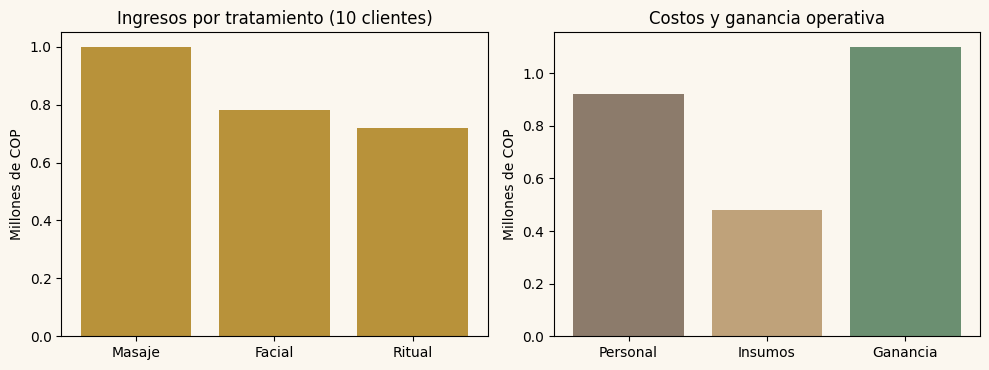

Fuente: cálculos propios con supuestos de simulación.


In [ ]:
# ==================  ESCRIBA AQUÍ LOS CLIENTES ESPERADOS  ==================
clientes_esperados = 16
# ==========================================================================

consultar_jornada(clientes_esperados)

**Ejemplo de demanda superior a la capacidad.** Con 30 clientes, el programa avisa que el spa no puede atenderlos y no muestra costos ni ganancia:

In [ ]:
consultar_jornada(30)

REPORTE DE JORNADA · Sunny Side Luxury Spa
Clientes esperados: 30

*** NO SE PUEDE ATENDER ESTA DEMANDA ***
Capacidad máxima del spa: 24 clientes por jornada
(8 cabinas × 3 clientes por terapeuta).
Clientes que quedarían sin atender: 6 de 30.

No se muestran costos, ingresos ni ganancia, porque esta
operación no es viable con la infraestructura disponible.
Reduzcan la demanda a 24 clientes o menos,
o amplíen las cabinas en los supuestos de la sección 2.


## 5 · Comparación de escenarios

Los tres escenarios usan **los mismos precios, costos y capacidades**. Solo cambia el número de clientes: un tercio, dos tercios y el total de la capacidad máxima.

In [ ]:
# Calcular los tres escenarios con la misma función
resultados_escenarios = []
for i in range(len(nombres_escenarios)):
    resultado = calcular_jornada(clientes_escenarios[i])
    resultados_escenarios.append(resultado)

# Armar la tabla comparativa: cada escenario es una columna
nombres_filas = [
    "Clientes", "Terapeutas", "Recepción/apoyo",
    "Costo de personal", "Costo de insumos", "Costos totales",
    "Ingresos totales", "Ganancia operativa estimada",
    "Margen sobre ingresos", "Utilización de terapeutas",
]

columnas_tabla = {}
for i in range(len(nombres_escenarios)):
    r = resultados_escenarios[i]
    columnas_tabla[nombres_escenarios[i]] = [
        r["clientes"],
        r["terapeutas"],
        r["recepcion"],
        formato_cop(r["costo_personal"]),
        formato_cop(r["costo_insumos"]),
        formato_cop(r["costos_totales"]),
        formato_cop(r["ingresos_total"]),
        formato_cop(r["ganancia"]),
        f"{r['margen']:.1f} %",
        f"{r['utilizacion']:.1f} %",
    ]

tabla_escenarios = pd.DataFrame(columnas_tabla, index=nombres_filas)
print("Tabla 1. Comparación de escenarios (supuestos de simulación, COP por jornada)")
tabla_escenarios

Tabla 1. Comparación de escenarios (supuestos de simulación, COP por jornada)


,Baja afluencia,Ocupación media,Agenda llena
Clientes,8,16,24
Terapeutas,3,6,8
Recepción/apoyo,1,2,3
Costo de personal,$720.000,$1.440.000,$1.960.000
Costo de insumos,$400.000,$760.000,$1.160.000
Costos totales,$1.120.000,$2.200.000,$3.120.000
Ingresos totales,$2.040.000,$3.980.000,$6.020.000
Ganancia operativa estimada,$920.000,$1.780.000,$2.900.000
Margen sobre ingresos,45.1 %,44.7 %,48.2 %
Utilización de terapeutas,88.9 %,88.9 %,100.0 %


In [ ]:
# Ingresos por tratamiento en cada escenario
nombres_filas_ingresos = nombres_servicios + ["Total"]

columnas_ingresos = {}
for i in range(len(nombres_escenarios)):
    r = resultados_escenarios[i]
    filas = []
    for j in range(len(nombres_servicios)):
        filas.append(formato_cop(r["ingresos_servicio"][j]))
    filas.append(formato_cop(r["ingresos_total"]))
    columnas_ingresos[nombres_escenarios[i]] = filas

tabla_ingresos = pd.DataFrame(columnas_ingresos, index=nombres_filas_ingresos)
print("Tabla 2. Ingresos por tratamiento y escenario (COP por jornada)")
tabla_ingresos

Tabla 2. Ingresos por tratamiento y escenario (COP por jornada)


,Baja afluencia,Ocupación media,Agenda llena
Masaje relajante,$800.000,$1.600.000,$2.400.000
Facial hidratante premium,$520.000,$1.300.000,$1.820.000
Ritual corporal,$720.000,$1.080.000,$1.800.000
Total,$2.040.000,$3.980.000,$6.020.000


**Figura 1.** Ingresos, costos totales y ganancia de cada escenario (misma escala vertical en los tres gráficos).

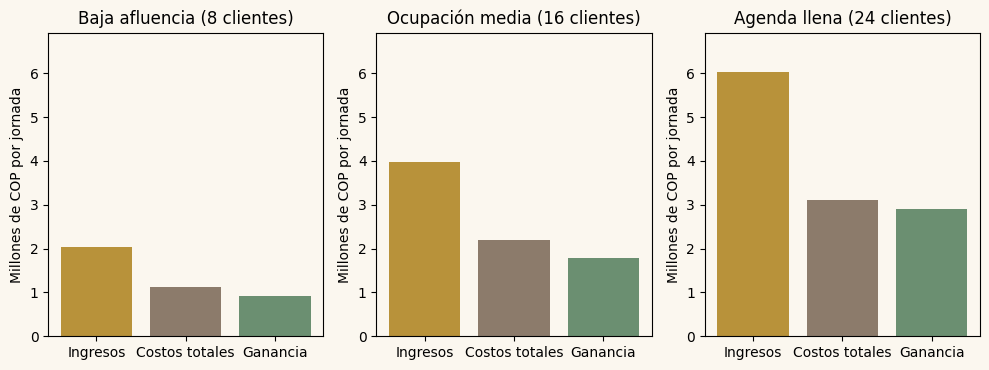

Fuente: cálculos propios con supuestos de simulación.


In [ ]:
# Pasar los resultados a millones de pesos para que el eje sea legible
ingresos_lista = []
costos_lista = []
ganancias_lista = []
for r in resultados_escenarios:
    ingresos_lista.append(r["ingresos_total"] / 1000000)
    costos_lista.append(r["costos_totales"] / 1000000)
    ganancias_lista.append(r["ganancia"] / 1000000)

tope = max(ingresos_lista) * 1.15       # mismo límite vertical para los tres gráficos

plt.figure(figsize=(10, 3.8), facecolor=color_fondo)
for i in range(len(nombres_escenarios)):
    plt.subplot(1, 3, i + 1, facecolor=color_fondo)     # 1 fila, 3 columnas, posición i+1
    plt.bar(
        ["Ingresos", "Costos totales", "Ganancia"],
        [ingresos_lista[i], costos_lista[i], ganancias_lista[i]],
        color=[color_oro, color_taupe, color_salvia]
    )
    plt.title(f"{nombres_escenarios[i]} ({clientes_escenarios[i]} clientes)")
    plt.ylabel("Millones de COP por jornada")
    plt.ylim(0, tope)
plt.tight_layout()
plt.show()
print("Fuente: cálculos propios con supuestos de simulación.")

**Figura 2.** Cómo cambian ingresos, costos y ganancia según el número de clientes. Los costos suben **en escalones**: cada vez que se supera la capacidad de un terapeuta o de recepción hay que contratar a otra persona.

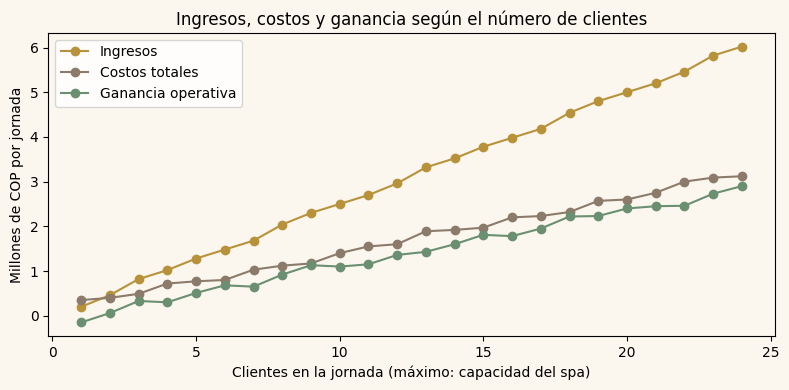

Fuente: cálculos propios con supuestos de simulación.


In [ ]:
clientes_eje = []
ingresos_eje = []
costos_eje = []
ganancia_eje = []

for n in range(1, capacidad_maxima + 1):
    r = calcular_jornada(n)
    clientes_eje.append(n)
    ingresos_eje.append(r["ingresos_total"] / 1000000)
    costos_eje.append(r["costos_totales"] / 1000000)
    ganancia_eje.append(r["ganancia"] / 1000000)

plt.figure(figsize=(8, 4), facecolor=color_fondo)
plt.subplot(1, 1, 1, facecolor=color_fondo)
plt.plot(clientes_eje, ingresos_eje, marker="o", color=color_oro, label="Ingresos")
plt.plot(clientes_eje, costos_eje, marker="o", color=color_taupe, label="Costos totales")
plt.plot(clientes_eje, ganancia_eje, marker="o", color=color_salvia, label="Ganancia operativa")
plt.title("Ingresos, costos y ganancia según el número de clientes")
plt.xlabel("Clientes en la jornada (máximo: capacidad del spa)")
plt.ylabel("Millones de COP por jornada")
plt.legend()
plt.tight_layout()
plt.show()
print("Fuente: cálculos propios con supuestos de simulación.")

## 6 · Verificación matemática

Antes de confiar en el programa, comparamos sus resultados con **cuentas hechas a mano** y revisamos que no haya inconsistencias internas. Cada línea debe decir OK.

> **Aviso.** Los valores esperados se calcularon a mano con los supuestos actuales. Si se cambia un supuesto en la sección 2, hay que recalcularlos a mano; de lo contrario esta celda mostrará ERROR aunque el programa esté bien.

In [ ]:
# ---------- Prueba 1: terapeutas y ganancia contra cuentas a mano ----------
casos_clientes = [8, 16, 24, 10, 15, 5, 1]
terapeutas_esperados = [3, 6, 8, 4, 5, 2, 1]
ganancias_esperadas = [920000, 1780000, 2900000, 1100000, 1810000, 510000, -150000]

print("PRUEBA 1 · Resultados contra cuentas a mano")
for i in range(len(casos_clientes)):
    r = calcular_jornada(casos_clientes[i])
    if r["terapeutas"] == terapeutas_esperados[i] and r["ganancia"] == ganancias_esperadas[i]:
        print(" ", casos_clientes[i], "clientes → OK | terapeutas:", r["terapeutas"], "| ganancia:", formato_cop(r["ganancia"]))
    else:
        print(" ", casos_clientes[i], "clientes → ERROR | el programa dio", r["terapeutas"], "terapeutas y ganancia", formato_cop(r["ganancia"]))

# ---------- Prueba 2: ejemplo de redondeo hacia arriba del personal ----------
print()
print("PRUEBA 2 · 9 clientes con capacidad 4 →", personal_necesario(9, 4), "(esperado: 3)")

# ---------- Prueba 3: el redondeo de 15 clientes (empate de 4,5) ----------
print()
print("PRUEBA 3 · Reparto de 15 clientes →", repartir_clientes(15), "(esperado: [7, 5, 3])")

# ---------- Prueba 4: consistencia interna de 1 a la capacidad máxima ----------
errores = 0
for n in range(1, capacidad_maxima + 1):
    r = calcular_jornada(n)
    suma_reparto = r["clientes_servicio"][0] + r["clientes_servicio"][1] + r["clientes_servicio"][2]
    suma_ingresos = r["ingresos_servicio"][0] + r["ingresos_servicio"][1] + r["ingresos_servicio"][2]
    if suma_reparto != n:
        errores = errores + 1
        print("  ERROR: el reparto no suma el total con", n, "clientes")
    if suma_ingresos != r["ingresos_total"]:
        errores = errores + 1
        print("  ERROR: los ingresos por tratamiento no suman el total con", n, "clientes")
    if r["ingresos_total"] - r["costos_totales"] != r["ganancia"]:
        errores = errores + 1
        print("  ERROR: ingresos - costos no es igual a la ganancia con", n, "clientes")
    if r["terapeutas"] > cabinas:
        errores = errores + 1
        print("  ERROR: se necesitan más terapeutas que cabinas con", n, "clientes")
print()
print("PRUEBA 4 · Consistencia interna de 1 a", capacidad_maxima, "clientes → errores encontrados:", errores)

# ---------- Prueba 5: demanda superior a la capacidad ----------
r = calcular_jornada(capacidad_maxima + 1)
print()
if r["viable"] == False and r["clientes_sin_atender"] == 1:
    print("PRUEBA 5 · Con", capacidad_maxima + 1, "clientes → OK | no es viable y 1 cliente queda sin atender")
else:
    print("PRUEBA 5 · ERROR: la demanda superior a la capacidad no se detectó")

PRUEBA 1 · Resultados contra cuentas a mano
  8 clientes → OK | terapeutas: 3 | ganancia: $920.000
  16 clientes → OK | terapeutas: 6 | ganancia: $1.780.000
  24 clientes → OK | terapeutas: 8 | ganancia: $2.900.000
  10 clientes → OK | terapeutas: 4 | ganancia: $1.100.000
  15 clientes → OK | terapeutas: 5 | ganancia: $1.810.000
  5 clientes → OK | terapeutas: 2 | ganancia: $510.000
  1 clientes → OK | terapeutas: 1 | ganancia: -$150.000

PRUEBA 2 · 9 clientes con capacidad 4 → 3 (esperado: 3)

PRUEBA 3 · Reparto de 15 clientes → [7, 5, 3] (esperado: [7, 5, 3])

PRUEBA 4 · Consistencia interna de 1 a 24 clientes → errores encontrados: 0

PRUEBA 5 · Con 25 clientes → OK | no es viable y 1 cliente queda sin atender


  ## 7 · Interpretación de resultados

<div style="background-color:#F5EDE0; border-left:5px solid #B8923A; padding:12px 18px; color:#4A3F35;">

</div>

1. **La ganancia crece con la ocupación.** Pasa de 920.000 con 8 clientes a 1.780.000 con 16 y a 2.900.000 con 24. Al triplicar los clientes, la ganancia se multiplica por un poco más de 3.
2. **El margen no crece de forma pareja.** Es 45,1 % con 8 clientes, 44,7 % con 16 y 48,2 % con 24. Entre 8 y 16 el costo de personal por cliente es igual (90.000), y la pequeña baja se explica por el redondeo de la mezcla de tratamientos (con 8 clientes hay 2 rituales, un 25 %, y con 16 hay 3, un 19 %). Entre 16 y 24 el margen sube porque los terapeutas pasan de una utilización de 88,9 % a 100 %, y el costo de personal por cliente baja de 90.000 a cerca de 81.700.
3. **Los costos de personal suben en escalones.** Con 3 clientes la ganancia es 330.000, y con 4 baja a 300.000 porque hay que contratar un segundo terapeuta. Agregar un cliente puede reducir la ganancia si obliga a contratar a otra persona (Figura 2).
4. **Qué podría decidir el administrador.** Conviene armar los turnos para que los terapeutas contratados queden lo más ocupados posible, y tener presente que el spa no puede atender más de 24 clientes por jornada con 8 cabinas.
5. **Cuidado con la lectura.** La ganancia es operativa y no incluye arriendo ni otros costos fijos, por eso aparece positiva desde 2 clientes. No debe leerse como la utilidad total del spa.


## 8 · Limitaciones del modelo

- Todas las cifras son supuestos de simulación del grupo, no datos reales.
- La ganancia es **operativa**: no incluye arriendo, servicios públicos, impuestos, marketing ni depreciación. Con esos costos fijos, la ganancia real sería menor.
- Se contrata solo el personal estrictamente necesario. Un spa real suele mantener un equipo mínimo aunque haya pocos clientes.
- Se supone que todos los tratamientos ocupan a un terapeuta durante un tiempo similar. En la realidad, cada tratamiento tiene una duración distinta.
- Se supone que todas las reservas se cumplen (sin cancelaciones ni inasistencias) y que la mezcla de tratamientos es constante. Con pocos clientes, esa mezcla no puede respetarse exactamente por el redondeo.
- La capacidad máxima depende solo de las cabinas. No se modelan horarios por franja ni días con distinta capacidad.
- No se modelan propinas, descuentos ni horas extra.

## 9 · Nota sobre el uso de inteligencia artificial

<div style="background-color:#F5EDE0; border-left:5px solid #B8923A; padding:12px 18px; color:#4A3F35;">

</div>

- **Herramienta:** Claude
- **Para qué la usamos:**
  1. Proponer el diseño de la aplicación y las fórmulas
  2. Revisar errores. Por ejemplo, la IA ayudó a detectar que la versión inicial seguía mostrando costos y ganancia cuando la demanda superaba la capacidad, y que `round()` trataba distinto empates iguales
  3. Preparar preguntas de práctica en base a nuestro docuemento para esta rlistos para la expocision
